# EDA Hari 2 — Versi Lengkap

**Pelatihan ML untuk Operasi PLTP · Hari 2 · 08.30–12.00**

Sebelum membuat model, kita harus **percaya pada data**. Kita periksa data dalam empat lapis:

| Lapis | Langkah | Pertanyaan |
|---|---|---|
| 1 · Kualitas | 1–4 | Apakah data bisa dipercaya? Apa yang harus diperbaiki? |
| 2 · Satu kolom | 5–6 | Seperti apa bulan yang "normal"? Mana yang ekstrem? |
| 3 · Hubungan | 7–8 | Perbandingan mana yang adil? Kolom mana yang mirip? |
| 4 · Waktu | 9–10 | Adakah pola bulanan? Apa penyebabnya? |
| Simpan | 11–12 | Simpan data bersih, tulis 5 kalimat temuan |

**Singkatan yang dipakai:**

| Singkatan | Kepanjangan | Arti sederhana |
|---|---|---|
| EDA | *Exploratory Data Analysis* | menjelajah data sebelum membuat model |
| CF | *Capacity Factor* | energi yang dihasilkan ÷ energi maksimum bila unit jalan penuh sebulan (%) |
| MW / MWh | megawatt / megawatt-jam | besar daya unit / jumlah energi yang dihasilkan |
| MO | *Maintenance Outage* | unit berhenti karena perawatan **terencana** |
| FO | *Forced Outage* | unit berhenti **mendadak** (tidak terencana) |
| PD / FD | *Planned / Forced Derating* | unit tetap jalan, tetapi di bawah daya penuh |
| IQR | *Interquartile Range* | lebar 50 % data yang di tengah; dipakai mencari outlier |
| n | — | jumlah data (mis. jumlah unit-bulan) |
| r | koefisien korelasi | skor −1 sampai +1: seberapa kompak dua kolom naik/turun bersama |
| Q1 · Q2 · Q3 | pertanyaan manajemen | Q1 jendela perawatan · Q2 risiko forced outage · Q3 harga wajar dan janji produksi |
| ARL, BTL, CKR, DRG, EKL, FRS | kode unit | Arloka, Bantala, Cakrawana, Dirgantara, Ekalaya, Farasindo |

**Ini versi lengkap (kunci jawaban)** dari `eda-hari2-kerangka.ipynb`: semua kode dan contoh jawaban sudah terisi.
Pakai untuk mencocokkan hasil, atau bila asisten AI tidak bisa diakses.

## 0 · Persiapan (sudah jadi — tinggal jalankan)

In [1]:
# Persiapan: library, data, dan gaya grafik
import sys
sys.path.insert(0, "..")

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import gaya_grafik as gg

gg.terapkan()

mentah   = pd.read_csv("../data/produksi_bulanan.csv")   # data MENTAH — jangan diubah
gangguan = pd.read_csv("../data/gangguan.csv")
unit     = pd.read_csv("../data/unit_pembangkit.csv")

print("mentah  :", mentah.shape)
print("gangguan:", gangguan.shape)
print("unit    :", unit.shape)

mentah  : (1081, 10)
gangguan: (200, 8)
unit    : (6, 6)


---
# Lapis 1 · Kualitas data

**Yang dipelajari:** menemukan nilai kosong, penulisan tidak konsisten, baris ganda, dan tipe kolom yang salah — lalu memutuskan cara memperbaikinya.
*Toko es krim: buku penjualan yang ada hari kosong, "Vanilla" dan "vanilla" terhitung dua rasa, dan hari Senin tercatat dua kali. Rapikan bukunya sebelum menghitung.*

## Langkah 1 · Satu baris itu apa?

**Prompt:**
> Tampilkan ukuran `mentah` (baris × kolom), lima baris pertama, dan tipe data tiap kolom. Jelaskan satu baris mewakili apa. **Jangan ubah `mentah`.**

In [2]:
# Ukuran tabel dan tipe tiap kolom
print("Ukuran:", mentah.shape)
print(mentah.dtypes)

# Lima baris pertama: satu baris = satu unit dalam satu bulan
mentah.head()

Ukuran: (1081, 10)
tanggal                object
tahun                   int64
bulan                   int64
kode_unit              object
uap_rencana_ton       float64
uap_aktual_ton        float64
energi_rencana_mwh    float64
energi_aktual_mwh     float64
jam_operasi           float64
cf_persen             float64
dtype: object


,tanggal,tahun,bulan,kode_unit,uap_rencana_ton,uap_aktual_ton,energi_rencana_mwh,energi_aktual_mwh,jam_operasi,cf_persen
0,2011-01-01,2011,1,ARL,483944.5,458042.1,70136.9,67334.2,744.0,82.28
1,2011-01-01,2011,1,BTL,416220.4,407225.0,54765.8,54471.7,744.0,86.13
2,2011-01-01,2011,1,CKR,303641.3,301168.4,39952.8,39558.5,744.0,88.62
3,2011-01-01,2011,1,DRG,277890.7,269213.5,29562.8,29474.0,744.0,88.03
4,2011-01-01,2011,1,EKL,189037.0,191627.9,20110.3,20593.3,744.0,92.26


In [3]:
# Cek
print("Baris  :", len(mentah), "(seharusnya 6 unit × 180 bulan = 1080 — kenapa lebih?)")
print("Kolom  :", mentah.shape[1], "(harus 10)")

Baris  : 1081 (seharusnya 6 unit × 180 bulan = 1080 — kenapa lebih?)
Kolom  : 10 (harus 10)


## Langkah 2 · Cari masalah (jangan diperbaiki dulu)

**Prompt:**
> Baca `AGENTS.md` dan `data/kamus_data.md`. Periksa `mentah`: (1) jumlah nilai kosong per kolom, (2) nilai unik `kode_unit` dan jumlahnya, (3) jumlah baris duplikat, (4) min dan max tiap kolom angka. **Jangan ubah apa pun.**

In [4]:
# 1) Kelengkapan: nilai kosong per kolom
print(mentah.isna().sum())

# 2) Konsistensi: kode unit dan jumlah barisnya
print(mentah["kode_unit"].value_counts())

# 3) Keunikan: baris yang sama persis
print("Baris duplikat:", mentah.duplicated().sum())

# 4) Validitas: nilai terkecil dan terbesar
mentah.describe().loc[["min", "max"]].round(1)

tanggal                0
tahun                  0
bulan                  0
kode_unit              0
uap_rencana_ton        0
uap_aktual_ton         0
energi_rencana_mwh     0
energi_aktual_mwh     12
jam_operasi            0
cf_persen              0
dtype: int64
kode_unit
ARL    180
CKR    180
DRG    180
EKL    180
FRS    180
BTL    178
arl      1
btl      1
Btl      1
Name: count, dtype: int64
Baris duplikat: 1


,tahun,bulan,uap_rencana_ton,uap_aktual_ton,energi_rencana_mwh,energi_aktual_mwh,jam_operasi,cf_persen
min,2011.0,1.0,8788.2,8508.3,934.9,905.4,24.0,2.6
max,2025.0,12.0,512301.7,542633.6,74246.6,77609.5,744.0,94.8


In [5]:
# Cek
print("Kode unit     :", mentah["kode_unit"].nunique(), "(seharusnya 6)")
print("Duplikat      :", mentah.duplicated().sum())
print("Energi kosong :", mentah["energi_aktual_mwh"].isna().sum())

Kode unit     : 9 (seharusnya 6)
Duplikat      : 1
Energi kosong : 12


**Contoh jawaban:**

- Temuan mana yang **salah data**, dan mana yang mungkin **kejadian nyata**?
  - *Jawab:* Kode unit huruf kecil/berspasi dan 1 baris ganda adalah salah data. CF rendah (min jauh di bawah 80 %) masih mungkin kejadian nyata (gangguan/perawatan), jadi belum boleh dibuang.

## Langkah 3 · Perbaiki satu per satu

Mulai sekarang kita bekerja di `df` (salinan). `mentah` tetap utuh.

In [6]:
df = mentah.copy()   # salinan kerja
print("df:", df.shape)

df: (1081, 10)


**3a · Kode unit.** Prompt:
> Pada `df`, hapus spasi di awal/akhir `kode_unit` lalu jadikan huruf besar. Cetak jumlah unit sebelum dan sesudah.

In [7]:
print("Sebelum:", df["kode_unit"].nunique(), "unit")
df["kode_unit"] = df["kode_unit"].str.strip().str.upper()
print("Sesudah:", df["kode_unit"].nunique(), "unit")
print(df["kode_unit"].value_counts())

Sebelum: 9 unit
Sesudah: 6 unit
kode_unit
ARL    181
BTL    180
CKR    180
DRG    180
EKL    180
FRS    180
Name: count, dtype: int64


**3b · Duplikat — lihat dulu.** Prompt:
> Tampilkan baris duplikat di `df` (kedua salinannya, `keep=False`). **Jangan hapus dulu.**

In [8]:
# Tampilkan kedua salinan baris yang ganda
df[df.duplicated(keep=False)]

,tanggal,tahun,bulan,kode_unit,uap_rencana_ton,uap_aktual_ton,energi_rencana_mwh,energi_aktual_mwh,jam_operasi,cf_persen
966,2024-06-01,2024,6,ARL,481567.4,478674.9,69792.4,68607.3,720.0,86.63
1080,2024-06-01,2024,6,ARL,481567.4,478674.9,69792.4,68607.3,720.0,86.63


Sudah dilihat dan setuju? Prompt:
> Hapus baris duplikat dari `df`, reset index, lalu cetak jumlah baris sebelum dan sesudah.

In [9]:
print("Sebelum:", len(df))
df = df.drop_duplicates().reset_index(drop=True)
print("Sesudah:", len(df))

Sebelum: 1081
Sesudah: 1080


**3c · Tanggal.** Prompt:
> Ubah kolom `tanggal` di `df` menjadi tipe datetime. Tampilkan tanggal paling awal dan paling akhir.

In [10]:
df["tanggal"] = pd.to_datetime(df["tanggal"])
print("Tipe :", df["tanggal"].dtype)
print("Awal :", df["tanggal"].min().date())
print("Akhir:", df["tanggal"].max().date())

Tipe : datetime64[ns]
Awal : 2011-01-01
Akhir: 2025-12-01


In [11]:
# Cek
print("Baris df     :", len(df), "(harus 1080)")
print("Jumlah unit  :", df["kode_unit"].nunique(), "(harus 6)")
print("Bulan ganda  :", df.duplicated(["tanggal", "kode_unit"]).sum(), "(harus 0)")
print("Baris mentah :", len(mentah), "(harus tetap 1081)")

Baris df     : 1080 (harus 1080)
Jumlah unit  : 6 (harus 6)
Bulan ganda  : 0 (harus 0)
Baris mentah : 1081 (harus tetap 1081)


## Langkah 4 · Nilai kosong: cari sebabnya dulu

**4a · Lihat barisnya.** Prompt:
> Tampilkan baris `df` yang `energi_aktual_mwh`-nya kosong, dengan kolom `tanggal`, `kode_unit`, `cf_persen`, `jam_operasi`. Apakah unitnya sebenarnya beroperasi? **Jangan isi dulu.**

In [12]:
kosong = df[df["energi_aktual_mwh"].isna()]
print("Jumlah baris kosong:", len(kosong))
kosong[["tanggal", "kode_unit", "cf_persen", "jam_operasi"]]

Jumlah baris kosong: 12


,tanggal,kode_unit,cf_persen,jam_operasi
21,2011-04-01,DRG,85.94,720.0
46,2011-08-01,EKL,85.98,744.0
242,2014-05-01,CKR,88.38,744.0
297,2015-02-01,DRG,86.20,672.0
429,2016-12-01,DRG,83.05,744.0
500,2017-12-01,CKR,85.92,744.0
540,2018-07-01,ARL,65.75,552.0
619,2019-08-01,BTL,84.63,744.0
632,2019-10-01,CKR,85.36,744.0
697,2020-09-01,BTL,44.41,384.0


**4b · Putuskan.** Pilih satu, lalu catat alasannya di `prompt-log.md`:

| Pilihan | Risiko |
|---|---|
| Hapus 12 baris | unit-bulan itu hilang dari semua analisis |
| Isi dengan 0 | mencatat 12 bulan "mati" yang tidak pernah terjadi |
| Isi dari CF × kapasitas × jam, beri penanda `energi_diisi` | angkanya perkiraan, bukan hasil ukur |

**Prompt** (sesuaikan dengan pilihan Anda):
> Isi `energi_aktual_mwh` yang kosong di `df` dengan `cf_persen/100 × kapasitas_mw × jam dalam bulan` (`kapasitas_mw` dari `unit`). Tambahkan kolom `energi_diisi` (True untuk baris yang diisi). Jangan hapus baris. Cetak jumlah baris dan sisa nilai kosong.

In [13]:
# Kapasitas tiap baris, diambil dari tabel unit
kapasitas = df["kode_unit"].map(unit.set_index("kode_unit")["kapasitas_mw"])
jam_bulan = df["tanggal"].dt.days_in_month * 24
perkiraan = df["cf_persen"] / 100 * kapasitas * jam_bulan

# Tandai dulu, baru isi
df["energi_diisi"] = df["energi_aktual_mwh"].isna()
df["energi_aktual_mwh"] = df["energi_aktual_mwh"].fillna(perkiraan)

print("Baris        :", len(df))
print("Baris diisi  :", df["energi_diisi"].sum())
print("Masih kosong :", df["energi_aktual_mwh"].isna().sum())

Baris        : 1080
Baris diisi  : 12
Masih kosong : 0


In [14]:
# Cek
print("Baris df       :", len(df), "(harus 1080)")
print("Ditandai diisi :", df["energi_diisi"].sum(), "(harus 12)")
df.loc[df["energi_diisi"], ["tanggal", "kode_unit", "cf_persen", "energi_aktual_mwh", "energi_rencana_mwh"]].round(0)

Baris df       : 1080 (harus 1080)
Ditandai diisi : 12 (harus 12)


,tanggal,kode_unit,cf_persen,energi_aktual_mwh,energi_rencana_mwh
21,2011-04-01,DRG,86.0,27845.0,28091.0
46,2011-08-01,EKL,86.0,19191.0,19694.0
242,2014-05-01,CKR,88.0,39453.0,39588.0
297,2015-02-01,DRG,86.0,26067.0,26369.0
429,2016-12-01,DRG,83.0,27805.0,28704.0
500,2017-12-01,CKR,86.0,38355.0,38934.0
540,2018-07-01,ARL,66.0,53810.0,69258.0
619,2019-08-01,BTL,85.0,53520.0,52580.0
632,2019-10-01,CKR,85.0,38105.0,37654.0
697,2020-09-01,BTL,44.0,27179.0,26855.0


**Contoh jawaban:**

- Kenapa mengisi dengan 0 itu salah untuk 12 baris ini?
  - *Jawab:* Karena unitnya beroperasi: CF 44–91 % dan jam operasi > 0. Energinya hanya tidak tercatat, bukan nol.
- Apa risikonya mengisi dari CF?
  - *Jawab:* CF sendiri dihitung dari energi, jadi angka isian hanya perkiraan. Karena itu ada kolom `energi_diisi`.

---
# Lapis 2 · Satu kolom: CF

**Yang dipelajari:** melihat sebaran satu kolom (histogram), membedakan rata-rata dan median, dan memeriksa outlier: salah data atau kejadian nyata?
*Toko es krim: biasanya laku 100 cone sehari; hari freezer rusak hanya 5. Hari itu menarik rata-rata turun, median hampir tidak berubah.*

## Langkah 5 · Seperti apa bulan yang normal?

**Prompt:**
> Buat histogram `cf_persen` di `df` dengan bin 5 % (0–100), pakai `gaya_grafik` (`gg`). Cetak rata-rata, median, minimum, dan maksimum. Lalu buat tabel per `kode_unit`: n, rata-rata, median, minimum.

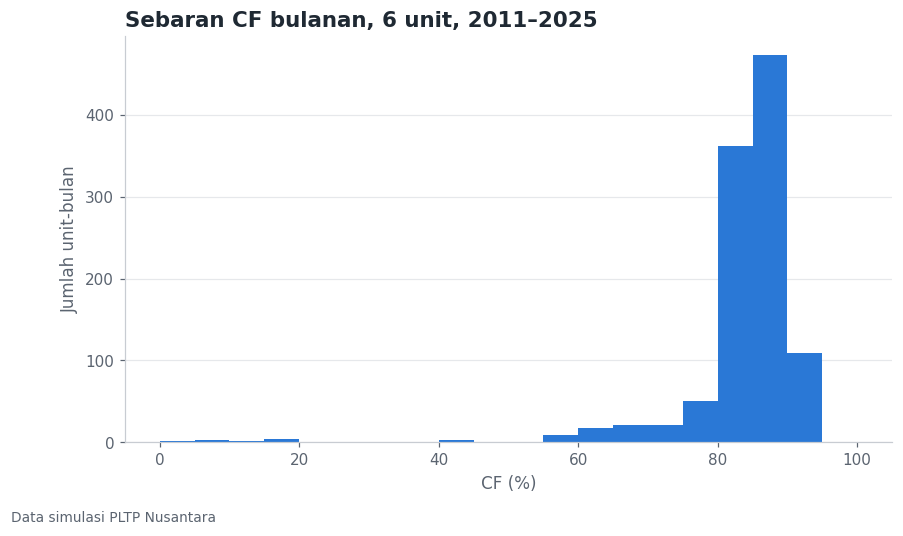

Rata-rata: 83.4
Median   : 85.3
Minimum  : 2.62
Maksimum : 94.83


,count,mean,median,min
kode_unit,,,,
ARL,180,84.5,85.7,19.6
BTL,180,82.8,84.8,5.4
CKR,180,84.5,86.8,2.6
DRG,180,82.5,84.8,2.7
EKL,180,83.5,85.3,8.4
FRS,180,82.9,84.6,16.0


In [15]:
# Histogram CF
fig, ax = plt.subplots()
ax.hist(df["cf_persen"], bins=range(0, 105, 5), color=gg.WARNA[0])
gg.rapikan(ax, "Sebaran CF bulanan, 6 unit, 2011–2025", "CF (%)", "Jumlah unit-bulan")
plt.show()

print("Rata-rata:", round(df["cf_persen"].mean(), 1))
print("Median   :", round(df["cf_persen"].median(), 1))
print("Minimum  :", df["cf_persen"].min())
print("Maksimum :", df["cf_persen"].max())

# Per unit
df.groupby("kode_unit")["cf_persen"].agg(["count", "mean", "median", "min"]).round(1)

In [16]:
# Cek
print("Rata-rata:", round(df["cf_persen"].mean(), 1), "(harus 83.4)")
print("Median   :", round(df["cf_persen"].median(), 1), "(harus 85.3)")

Rata-rata: 83.4 (harus 83.4)
Median   : 85.3 (harus 85.3)


## Langkah 6 · Bulan ekstrem: salah data atau kejadian nyata?

**6a · Cari outlier.** Prompt:
> Hitung batas outlier `cf_persen` di `df` dengan aturan IQR: batas bawah = kuartil 25 % − 1,5×IQR, batas atas = kuartil 75 % + 1,5×IQR. Cetak kedua batas dan jumlah outlier. Simpan baris outlier ke variabel `outlier` (salinan, kolom `tanggal`, `kode_unit`, `cf_persen`). **Jangan hapus apa pun dari `df`.**

In [17]:
kuartil_25 = df["cf_persen"].quantile(0.25)
kuartil_75 = df["cf_persen"].quantile(0.75)
iqr = kuartil_75 - kuartil_25          # lebar 50 % data di tengah
batas_bawah = kuartil_25 - 1.5 * iqr
batas_atas = kuartil_75 + 1.5 * iqr
print("Batas bawah:", round(batas_bawah, 1))
print("Batas atas :", round(batas_atas, 1))

terlalu_rendah = df["cf_persen"] < batas_bawah
terlalu_tinggi = df["cf_persen"] > batas_atas
print("Di bawah batas:", terlalu_rendah.sum())
print("Di atas batas :", terlalu_tinggi.sum())

outlier = df[terlalu_rendah | terlalu_tinggi][["tanggal", "kode_unit", "cf_persen"]].copy()

Batas bawah: 75.7
Batas atas : 94.9
Di bawah batas: 91
Di atas batas : 0


**6b · Cocokkan dengan catatan gangguan.** Prompt:
> Untuk setiap baris di `outlier`, cari gangguan di `gangguan` pada unit yang sama dan bulan yang berada di antara bulan `tanggal_mulai` dan `tanggal_selesai`. Tambahkan kolom `jenis` (jenis gangguan, gabung dengan koma) dan `ada_gangguan` (True/False). Pakai perulangan `for` yang mudah dibaca. Cetak berapa outlier yang punya gangguan, dan tampilkan outlier dengan CF < 50.

In [18]:
# Bulan mulai dan bulan selesai setiap gangguan
bulan_mulai = pd.to_datetime(gangguan["tanggal_mulai"]).dt.to_period("M")
bulan_selesai = pd.to_datetime(gangguan["tanggal_selesai"]).dt.to_period("M")

daftar_jenis = []
for i, baris in outlier.iterrows():
    bulan = baris["tanggal"].to_period("M")
    cocok = gangguan[
        (gangguan["kode_unit"] == baris["kode_unit"])
        & (bulan_mulai <= bulan)
        & (bulan_selesai >= bulan)
    ]
    daftar_jenis.append(", ".join(cocok["jenis"].unique()))

outlier["jenis"] = daftar_jenis
outlier["ada_gangguan"] = outlier["jenis"] != ""

print("Outlier dengan gangguan:", outlier["ada_gangguan"].sum(), "dari", len(outlier))
outlier[outlier["cf_persen"] < 50].sort_values("cf_persen")

Outlier dengan gangguan: 91 dari 91


,tanggal,kode_unit,cf_persen,jenis,ada_gangguan
662,2020-03-01,CKR,2.62,MO,True
159,2013-03-01,DRG,2.70,MO,True
235,2014-04-01,BTL,5.44,MO,True
232,2014-03-01,EKL,8.39,MO,True
236,2014-04-01,CKR,8.91,MO,True
807,2022-03-01,DRG,13.70,MO,True
1021,2025-03-01,BTL,14.35,MO,True
944,2024-02-01,CKR,15.03,MO,True
887,2023-04-01,FRS,16.00,MO,True
552,2018-09-01,ARL,19.61,MO,True


In [19]:
# Cek
print("Jumlah outlier         :", len(outlier), "(harus 91)")
print("Punya catatan gangguan :", outlier["ada_gangguan"].sum(), "(harus 91)")
print("CF < 50 yang ada MO    :", outlier[outlier["cf_persen"] < 50]["jenis"].str.contains("MO").sum(), "(harus 17)")
print("Baris df               :", len(df), "(harus tetap 1080)")

Jumlah outlier         : 91 (harus 91)
Punya catatan gangguan : 91 (harus 91)
CF < 50 yang ada MO    : 17 (harus 17)
Baris df               : 1080 (harus tetap 1080)


**Contoh jawaban:**

- Outlier ini salah data atau kejadian nyata? Apa buktinya?
  - *Jawab:* Kejadian nyata: semua 91 outlier bertepatan dengan catatan gangguan, dan 17 bulan dengan CF < 50 % semuanya ada MO.
- Apa yang terjadi pada model forced outage (Hari 3) kalau 91 baris ini dibuang?
  - *Jawab:* Model kehilangan justru contoh-contoh gangguan yang mau diprediksi, jadi outlier ini harus disimpan.
- Untuk manajer, angka mana yang lebih menggambarkan bulan biasa: rata-rata atau median?
  - *Jawab:* Median (85,3 %). Rata-rata (83,4 %) tertarik turun oleh beberapa bulan gangguan.

---
# Lapis 3 · Hubungan antar kolom

**Yang dipelajari:** membandingkan secara adil (pakai angka per ukuran, seperti CF) dan membaca korelasi *r* — tanpa langsung menyimpulkan sebab-akibat.
*Toko es krim: cabang mal laku 3× lebih banyak karena lebih besar, bukan lebih baik — bandingkan cone per karyawan. Hari panas → es krim laku, tetapi juga lebih banyak orang tenggelam: keduanya disebabkan cuaca panas.*

## Langkah 7 · Bandingkan yang sebanding

**7a · Energi atau CF?** Prompt:
> Gabungkan `df` dengan `unit` berdasarkan `kode_unit` (how="left") menjadi `df_unit`; cetak jumlah baris sebelum dan sesudah. Lalu hitung rata-rata `energi_aktual_mwh` dan `cf_persen` per unit. Berapa kali energi ARL dibanding FRS, dan berapa selisih CF-nya?

In [20]:
df_unit = df.merge(unit, on="kode_unit", how="left")
print("Baris sebelum:", len(df), "| sesudah:", len(df_unit))

energi = df.groupby("kode_unit")["energi_aktual_mwh"].mean()
cf = df.groupby("kode_unit")["cf_persen"].mean()
print("Energi ARL dibanding FRS:", round(energi["ARL"] / energi["FRS"], 1), "kali")
print("Selisih CF ARL − FRS    :", round(cf["ARL"] - cf["FRS"], 1), "poin %")

df_unit.groupby(["kode_unit", "kapasitas_mw"])[["energi_aktual_mwh", "cf_persen"]].mean().round(1)

Baris sebelum: 1080 | sesudah: 1080


Energi ARL dibanding FRS: 5.6 kali
Selisih CF ARL − FRS    : 1.6 poin %


,,energi_aktual_mwh,cf_persen
kode_unit,kapasitas_mw,,
ARL,110,67892.2,84.5
BTL,85,51388.2,82.8
CKR,60,37043.6,84.5
DRG,45,27126.7,82.5
EKL,30,18289.4,83.5
FRS,20,12115.9,82.9


**7b · Jenis turbin — selalu tampilkan n.** Prompt:
> Dari `df_unit`, buat tabel per `jenis_turbin`: jumlah unit, n (unit-bulan), rata-rata dan median `cf_persen`.

In [21]:
per_turbin = df_unit.groupby("jenis_turbin")["cf_persen"].agg(["count", "mean", "median"]).round(1)
per_turbin["jumlah_unit"] = df_unit.groupby("jenis_turbin")["kode_unit"].nunique()
per_turbin

,count,mean,median,jumlah_unit
jenis_turbin,,,,
Binary,540,83.0,84.8,3
Double Flash,180,84.5,85.7,1
Single Flash,360,83.6,85.7,2


In [22]:
# Cek
print("Baris df_unit       :", len(df_unit), "(harus 1080)")
print("jenis_turbin kosong :", df_unit["jenis_turbin"].isna().sum(), "(harus 0)")

Baris df_unit       : 1080 (harus 1080)
jenis_turbin kosong : 0 (harus 0)


## Langkah 8 · Kolom mana yang "bicara hal yang sama"?

**Prompt:**
> Hitung korelasi antara `uap_aktual_ton`, `energi_aktual_mwh`, `jam_operasi`, dan `cf_persen` di `df` (2 desimal). Buat scatter plot uap vs energi dengan warna per unit dari `gg.warna_unit`.

                   uap_aktual_ton  energi_aktual_mwh  jam_operasi  cf_persen
uap_aktual_ton               1.00               0.99         0.26       0.29
energi_aktual_mwh            0.99               1.00         0.21       0.25
jam_operasi                  0.26               0.21         1.00       0.92
cf_persen                    0.29               0.25         0.92       1.00


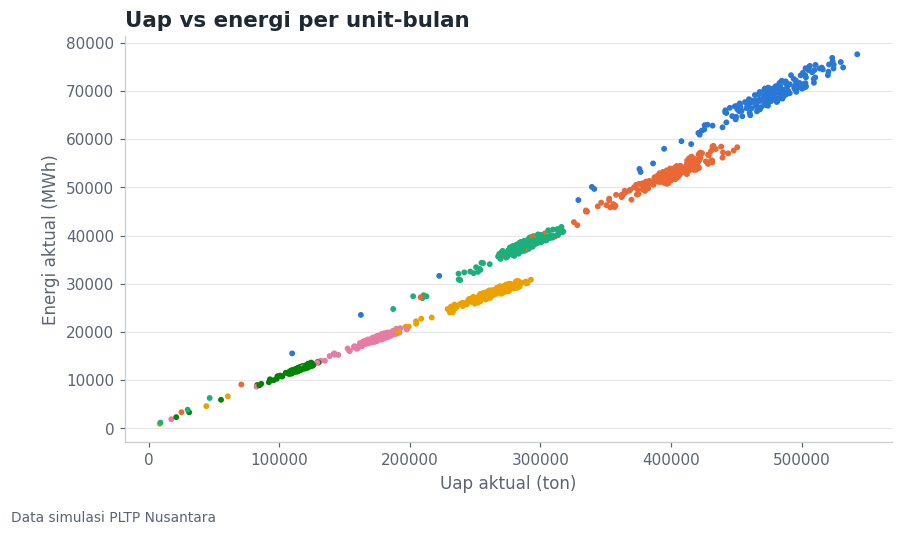

In [23]:
kolom = ["uap_aktual_ton", "energi_aktual_mwh", "jam_operasi", "cf_persen"]
print(df[kolom].corr().round(2))

fig, ax = plt.subplots()
ax.scatter(df["uap_aktual_ton"], df["energi_aktual_mwh"], s=8, c=gg.warna_unit(df["kode_unit"]))
gg.rapikan(ax, "Uap vs energi per unit-bulan", "Uap aktual (ton)", "Energi aktual (MWh)")
plt.show()

In [24]:
# Cek
korelasi = df[["uap_aktual_ton", "energi_aktual_mwh", "jam_operasi", "cf_persen"]].corr()
print("r uap–energi :", round(korelasi.loc["uap_aktual_ton", "energi_aktual_mwh"], 2), "(sekitar 0.99)")
print("r jam–CF     :", round(korelasi.loc["jam_operasi", "cf_persen"], 2), "(sekitar 0.92)")

r uap–energi : 0.99 (sekitar 0.99)
r jam–CF     : 0.92 (sekitar 0.92)


**Contoh jawaban:**

- Apakah turbin Binary "lebih buruk"? Tulis satu kalimat yang **jujur**.
  - *Jawab:* CF Binary sedikit lebih rendah, tetapi unit Binary juga yang paling kecil, dan Double Flash hanya 1 unit (n = 180 unit-bulan), jadi jenis turbin belum bisa disebut sebagai penyebab.
- Uap vs energi r ≈ 0,99. Apakah ini penemuan? Apa artinya untuk memilih feature model?
  - *Jawab:* Bukan penemuan — energi memang dihasilkan dari uap. Keduanya membawa informasi yang sama, cukup pakai salah satu.

---
# Lapis 4 · Waktu

**Yang dipelajari:** memisahkan tren (naik/turun pelan), musim (berulang tiap tahun), dan kejadian sekali (mis. FO).
*Toko es krim: pelanggan bertambah tiap tahun (tren), ramai tiap kemarau (musim), tutup seminggu untuk renovasi (kejadian sekali).*

## Langkah 9 · Adakah pola bulanan?

**9a · Rata-rata vs median per bulan.** Prompt:
> Dari `df`, hitung rata-rata dan median `cf_persen` per `bulan` (1–12), simpan sebagai `per_bulan` dengan kolom `mean` dan `median`. Buat grafik garis dua garis itu.

       mean  median
bulan              
1      85.8    86.4
2      84.9    86.2
3      80.0    86.1
4      81.9    85.3
5      83.6    84.8
6      83.6    84.8
7      83.1    84.8
8      83.8    84.7
9      80.4    84.5
10     83.7    85.1
11     84.1    84.8
12     86.5    86.8


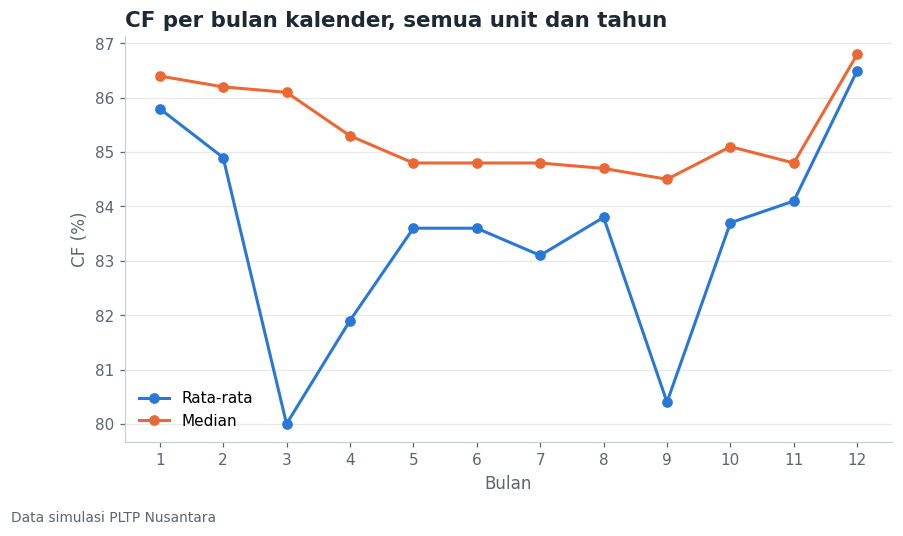

In [25]:
per_bulan = df.groupby("bulan")["cf_persen"].agg(["mean", "median"]).round(1)
print(per_bulan)

fig, ax = plt.subplots()
ax.plot(per_bulan.index, per_bulan["mean"], marker="o", label="Rata-rata")
ax.plot(per_bulan.index, per_bulan["median"], marker="o", label="Median")
ax.set_xticks(range(1, 13))
ax.legend()
gg.rapikan(ax, "CF per bulan kalender, semua unit dan tahun", "Bulan", "CF (%)", nol=False)
plt.show()

In [26]:
# Cek
print("Rata-rata Maret     :", per_bulan.loc[3, "mean"], "(harus 80.0)")
print("Rata-rata September :", per_bulan.loc[9, "mean"], "(harus 80.4)")
print("Median terendah     :", per_bulan["median"].min(), "(harus 84.5)")

Rata-rata Maret     : 80.0 (harus 80.0)
Rata-rata September : 80.4 (harus 80.4)
Median terendah     : 84.5 (harus 84.5)


**9b · Siapa yang menarik Maret turun?** Prompt:
> Tampilkan semua unit-bulan di bulan Maret dengan `cf_persen` di bawah 75 dari `df`, urutkan dari yang terendah.

In [27]:
maret_rendah = df[(df["bulan"] == 3) & (df["cf_persen"] < 75)]
print("Jumlah:", len(maret_rendah), "dari", (df["bulan"] == 3).sum(), "unit-bulan Maret")
maret_rendah[["tanggal", "kode_unit", "cf_persen"]].sort_values("cf_persen")

Jumlah: 12 dari 90 unit-bulan Maret


,tanggal,kode_unit,cf_persen
662,2020-03-01,CKR,2.62
159,2013-03-01,DRG,2.70
232,2014-03-01,EKL,8.39
807,2022-03-01,DRG,13.70
1021,2025-03-01,BTL,14.35
519,2018-03-01,DRG,19.78
228,2014-03-01,ARL,38.64
520,2018-03-01,EKL,61.07
590,2019-03-01,CKR,61.32
1025,2025-03-01,FRS,68.90


## Langkah 10 · Kapan perawatan (MO) dimulai?

**Prompt:**
> Dari `gangguan`, buat tabel silang jumlah kejadian per bulan `tanggal_mulai` (baris) dan `jenis` (kolom). Buat diagram batang khusus jenis MO. Jangan ubah `gangguan`.

jenis          FD  FO  MO  PD
tanggal_mulai                
1               4   5   0   4
2               8   7   1   2
3               8   9   7   2
4               1   4   4   3
5               2   8   0   4
6               6  11   0   1
7               5  12   0   3
8               5  11   0   3
9               0  10   5   4
10              3  10   0   2
11              4   6   0   5
12              3   6   0   2


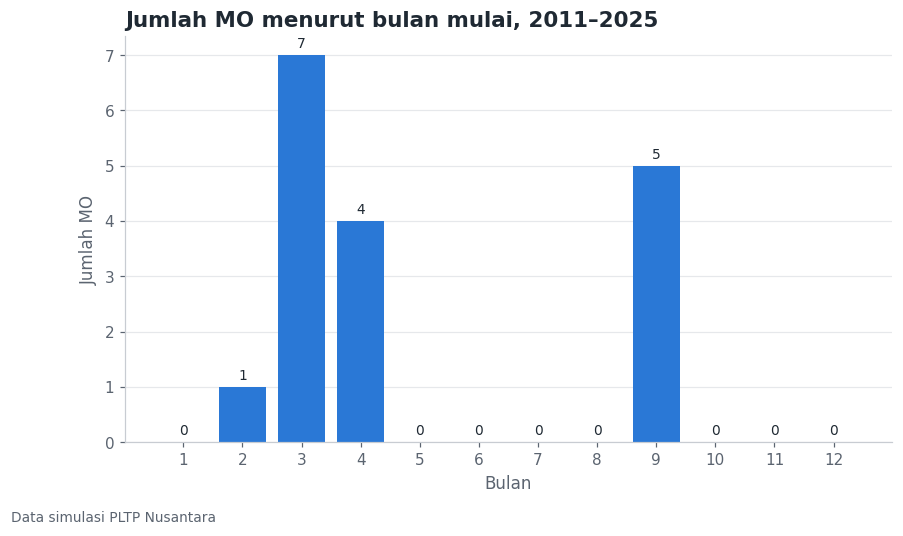

In [28]:
bulan_mulai_angka = pd.to_datetime(gangguan["tanggal_mulai"]).dt.month
tabel_silang = pd.crosstab(bulan_mulai_angka, gangguan["jenis"])
print(tabel_silang)

fig, ax = plt.subplots()
ax.bar(tabel_silang.index, tabel_silang["MO"], color=gg.WARNA[0])
ax.set_xticks(range(1, 13))
gg.label_batang(ax, "{:.0f}")
gg.rapikan(ax, "Jumlah MO menurut bulan mulai, 2011–2025", "Bulan", "Jumlah MO")
plt.show()

In [29]:
# Cek
print("MO mulai di Maret     :", tabel_silang.loc[3, "MO"], "(harus 7)")
print("MO mulai di September :", tabel_silang.loc[9, "MO"], "(harus 5)")

MO mulai di Maret     : 7 (harus 7)
MO mulai di September : 5 (harus 5)


**Contoh jawaban:**

- Rata-rata Maret turun, median tidak. Jelaskan dalam satu kalimat untuk manajer.
  - *Jawab:* Bukan semua unit yang turun di bulan Maret — hanya beberapa unit yang sedang perawatan, dan bulan-bulan sangat rendah itu menarik rata-rata ke bawah.
- Apa artinya untuk Q1 — pertanyaan manajemen soal jendela perawatan?
  - *Jawab:* Maret dan September sudah menjadi jendela perawatan de-facto. Clustering siang ini harus menguji apakah pola itu memang ada.

---
## Langkah 11 · Simpan data bersih

File ini dipakai di sesi siang (clustering).

**Prompt:**
> Simpan `df` ke `../data/olahan/produksi_bersih.csv` (buat folder bila belum ada). Sebelum menyimpan, tambahkan `assert`: 1.080 baris, 6 unit, tidak ada unit-bulan ganda.

In [30]:
# Pengaman: berhenti bila ada yang salah
assert len(df) == 1080, "df harus 1.080 baris"
assert df["kode_unit"].nunique() == 6, "df harus 6 unit"
assert not df.duplicated(["tanggal", "kode_unit"]).any(), "ada unit-bulan ganda"

Path("../data/olahan").mkdir(exist_ok=True)
df.to_csv("../data/olahan/produksi_bersih.csv", index=False)
print("Tersimpan:", len(df), "baris")

Tersimpan: 1080 baris


In [31]:
# Cek
bersih = pd.read_csv("../data/olahan/produksi_bersih.csv")
print("File bersih  :", len(bersih), "baris,", bersih["kode_unit"].nunique(), "unit (harus 1080, 6)")
print("energi_diisi :", "energi_diisi" in bersih.columns, "(harus True)")
print("CSV mentah   :", len(pd.read_csv("../data/produksi_bulanan.csv")), "baris (harus tetap 1081)")

File bersih  : 1080 baris, 6 unit (harus 1080, 6)
energi_diisi : True (harus True)
CSV mentah   : 1081 baris (harus tetap 1081)


## Langkah 12 · Lima kalimat temuan

1. **Kualitas:** File mentah berisi 1.081 baris; setelah 9 kode unit diseragamkan menjadi 6 dan 1 baris ganda dihapus, tersisa 1.080 baris (6 unit × 180 bulan). 12 nilai energi tidak tercatat padahal unit beroperasi (CF 44–91 %), jadi diisi dari CF dan diberi penanda, bukan diisi 0.
2. **Satu kolom:** Bulan biasa ber-CF sekitar 85 % (median 85,3 %); rata-rata (83,4 %) lebih rendah karena 91 bulan rendah — semuanya bertepatan dengan catatan gangguan, jadi tetap disimpan.
3. **Hubungan:** Unit Binary sedikit lebih rendah CF-nya, tetapi unit Binary juga yang paling kecil dan Double Flash hanya 1 unit, jadi jenis turbin belum bisa disebut sebagai penyebab.
4. **Waktu:** Rata-rata Maret (80,0 %) dan September (80,4 %) turun, sedangkan median tetap 84,5–86,8 %: hanya beberapa unit yang turun karena perawatan terencana (MO paling sering mulai di Maret, 7×, dan September, 5×).
5. **Untuk tim perawatan:** Maret–April dan September sudah menjadi jendela perawatan de-facto; clustering siang ini menguji pola itu memakai `data/olahan/produksi_bersih.csv`.

---
## Checkpoint 12.00

- [ ] `data/olahan/produksi_bersih.csv` ada: 1.080 baris, 6 unit, kolom `energi_diisi`
- [ ] notebook ini jalan dengan *Restart & Run All*
- [ ] lima kalimat temuan + keputusan nilai kosong ada di `prompt-log.md`

**Bisa menjelaskan:** kenapa 1.081 jadi 1.080 · kenapa nilai kosong tidak diisi 0 · kenapa outlier tidak dibuang · kenapa rata-rata Maret turun tapi median tidak.